[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/01_tensors.ipynb)

*Deep Learning & LLMs · Notebook 1 of 10*

# Tensors & Layers

The language of deep learning: tensor shapes and batches, dense layers, logits, softmax and stable cross-entropy, initialisation, and backpropagation through real matrices.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A tensor is a labelled stack of numbers. Most deep-learning bugs are shape bugs, so track the shape on every line.

**What interviewers really test here:** Shapes, broadcasting, parameter counts and activations.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What deep learning adds *(Basics)*
- [ ] 2. Tensors and shapes *(Basics)*
- [ ] 3. A dense layer by hand *(Basics)*
- [ ] 4. From logits to a loss, safely *(Core)*
- [ ] 5. Batches, steps and epochs *(Core)*
- [ ] 6. Backpropagation with matrices *(Core)*
- [ ] 7. Initialisation: why the starting numbers matter *(Advanced)*
- [ ] 8. The same network in PyTorch *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Core vocabulary

| Term | Meaning |
| --- | --- |
| Tensor | n-dimensional array |
| Dense / linear / fully connected layer | z = Wx + b |
| Activation | non-linearity applied after a layer |
| Logits | raw scores before softmax |
| Loss | a number measuring how wrong the model is |
| Forward pass | inputs → predictions |
| Backward pass | loss → gradient of every weight |
| Parameters | the weights and biases learned |
| Hyper-parameters | settings you choose: learning rate, depth, width |

### Numerical stability

- Sum logs instead of multiplying probabilities.
- Use the log-sum-exp trick: log Σ eᶻ = max(z) + log Σ e^(z − max z).
- Prefer losses that take logits (`BCEWithLogitsLoss`, `CrossEntropyLoss`).
- Float16 and mixed precision speed up training but need loss scaling to avoid underflow.

### Common shape bugs

| Bug | Symptom | Fix |
| --- | --- | --- |
| (n,) minus (n, 1) | silent n × n table; loss won't fall | squeeze one, or match shapes |
| Wrong flatten size | "mat1 and mat2 shapes" error | print the shape before the dense layer |
| Channels last vs first | wrong number of channels error | PyTorch wants (N, C, H, W) |
| Forgetting the batch dimension | errors on a single example | add one: `x.unsqueeze(0)` |

---
# Part 2: Lessons, step by step

## Lesson 1: What deep learning adds

*Level: Basics*

Classic ML needs you to design the features. **Deep learning learns the features too.** Each layer turns its input into something a little more useful: pixels into edges, edges into shapes, shapes into objects.



|   | Classic ML | Deep learning |
| --- | --- | --- |
| Features | designed by hand | learned |
| Best on | tables, small data | images, audio, text, large data |
| Needs | a CPU, minutes | often a GPU, hours or more |
| Interpretability | usually easier | harder |



**Honest advice:** for ordinary tables, gradient boosting often wins with far less effort. Use deep learning when the input is unstructured, or when you can use a pre-trained model.



Every deep model, including the largest language models, is built from what you'll learn here: tensors, layers, a loss, gradients and an update rule.

## Lesson 2: Tensors and shapes

*Level: Basics*

A **tensor** is an array with any number of dimensions. Reading shapes is the most useful daily skill in deep learning.



| Data | Shape | Means |
| --- | --- | --- |
| Table | (32, 20) | 32 rows, 20 features |
| Colour images (PyTorch) | (32, 3, 224, 224) | batch, channels, height, width |
| Token ids | (8, 100) | 8 texts, 100 tokens each |
| Token embeddings | (8, 100, 512) | each token is now a 512-number vector |
| Logits for next token | (8, 100, 50000) | a score for every word in the vocabulary, at every position |



The first dimension is nearly always the **batch**: we process many examples together, for speed and for steadier gradients.



**Debugging habit:** write the expected shape beside each line. Most deep learning bugs are shape bugs, and the quiet ones come from broadcasting.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [2]:
def shapes_demo():
    images = np.zeros((32, 3, 224, 224))
    flat = images.reshape(32, -1)
    tokens = np.zeros((8, 100), dtype=int)
    embedding_table = np.zeros((50000, 512))
    embedded = embedding_table[tokens]
    shapes = (images.shape, flat.shape, embedded.shape)
    silent_bug = (np.zeros((3,)) + np.zeros((3, 1))).shape


shapes_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q11](#q11), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 3: A dense layer by hand

*Level: Basics*

Input x = (1, 2), going into 3 neurons. W has one row per input and one column per neuron:



```python
W = [[0.5, -1.0,  2.0],     b = [0, 1, -1]
     [1.0,  0.0, -0.5]]
```



| Neuron | Calculation | z | ReLU(z) |
| --- | --- | --- | --- |
| 1 | 1(0.5) + 2(1.0) + 0 | 2.5 | 2.5 |
| 2 | 1(−1.0) + 2(0.0) + 1 | 0 | 0 |
| 3 | 1(2.0) + 2(−0.5) − 1 | 0 | 0 |



All at once: `Z = X @ W + b`. Then an output layer with weights (1, −0.5, 0.25) and bias 0.5 gives 2.5 + 0.5 = **3.0**.



#### Count the shapes



X is (1, 2), W is (2, 3), and X·W is (1, 3): **the inner sizes must match**. This layer has 2 × 3 + 3 = 9 parameters.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def dense_by_hand():
    X = np.array([[1.0, 2.0]])
    W = np.array([[0.5, -1.0, 2.0], [1.0, 0.0, -0.5]])
    b = np.array([0.0, 1.0, -1.0])
    Z = X @ W + b
    H = np.maximum(0, Z)
    output = H @ np.array([1.0, -0.5, 0.25]) + 0.5
    parameters = W.size + b.size


dense_by_hand()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 4: From logits to a loss, safely

*Level: Core*

A classifier's last layer gives raw scores called **logits**. Suppose they are (2, 1, 0) and the true class is the first.



1. **Softmax:** e² = 7.389, e¹ = 2.718, e⁰ = 1. These total 11.107, so the probabilities are 0.665, 0.245, 0.090.
2. **Cross-entropy:** −ln(0.665) = **0.408**.



#### Why not compute it that way in code?



With logits like 1000, e¹⁰⁰⁰ overflows to infinity, and very small probabilities round to 0, so ln 0 gives −∞. Work with logs directly:



```python
loss = log(Σ e^z) − z_true
log(Σ e^z) = max(z) + log(Σ e^(z − max(z)))     # the log-sum-exp trick
```



That's why PyTorch's `CrossEntropyLoss` takes **logits**. Applying softmax first is a classic bug: the model still trains, but worse.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def safe_loss():
    z = np.array([2.0, 1.0, 0.0])
    naive = -math.log(math.exp(z[0]) / np.exp(z).sum())
    big = np.array([1000.0, 0.0, 0.0])
    with np.errstate(over="ignore"):
        overflowed = np.exp(big).sum()
    shifted = big - big.max()
    log_sum = big.max() + np.log(np.exp(shifted).sum())
    safe = log_sum - big[0]


safe_loss()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q5](#q5), [Q14](#q14), [Q15](#q15), [Q7](#q7), [Q8](#q8), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 5: Batches, steps and epochs

*Level: Core*

| Word | Meaning |
| --- | --- |
| Batch | the examples used for one update |
| Step (iteration) | one update of the weights |
| Epoch | one full pass through the data |



**Worked example:** 10,000 rows with batch size 32 gives ⌈10000 / 32⌉ = **313 steps per epoch**, so 10 epochs make 3,130 updates.



#### Choosing a batch size



- **Small:** noisy gradients, more updates per epoch, less memory.
- **Large:** smoother gradients, faster per example on a GPU, but needs more memory.
- Common starting points: 32–256. If you run out of memory, halve it.



**Always shuffle** training data each epoch. If the data arrives sorted by class, each batch misleads the model. Don't shuffle time-ordered validation splits.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

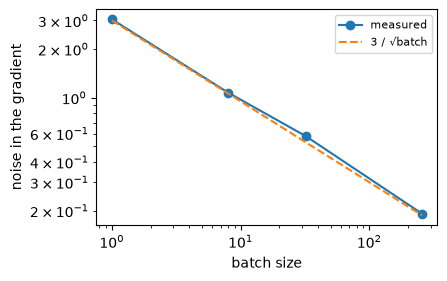

In [5]:
def batch_noise():
    r = np.random.default_rng(0)
    gradients = r.normal(1.0, 3.0, 100000)
    sizes = [1, 8, 32, 256]
    spreads = {b: round(float(gradients[:b * 300].reshape(-1, b).mean(axis=1).std()), 3) for b in sizes}
    fig, ax = plt.subplots(figsize=(4.4, 2.8))
    ax.loglog(sizes, list(spreads.values()), "o-", label="measured")
    ax.loglog(sizes, [3 / b ** 0.5 for b in sizes], "--", label="3 / √batch")
    ax.set_xlabel("batch size")
    ax.set_ylabel("noise in the gradient")
    ax.legend(fontsize=8)


batch_noise()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 6: Backpropagation with matrices

*Level: Core*

For H = tanh(X·W₁ + b₁), Ŷ = H·W₂ + b₂, with loss ½·mean((Ŷ − Y)²). Follow the shapes with n rows, d features and h hidden neurons:



| Step | Code | Shape |
| --- | --- | --- |
| Forward | `H = tanh(X @ W1 + b1)` | (n, h) |
|   | `Y_hat = H @ W2 + b2` | (n, 1) |
| Error | `E = Y_hat - Y` | (n, 1) |
| Into H | `dH = E @ W2.T * (1 - H**2)` | (n, h) |
| Into W1 | `X.T @ dH / n` | (d, h) |
| Into W2 | `H.T @ E / n` | (h, 1) |



**The rule to remember:** a gradient has the same shape as the thing it belongs to. If it doesn't, the code is wrong.



**Why go backwards?** `E @ W2.T` is shared by everything earlier, so computing from the output reuses it. Going forwards would repeat the work for every weight.



Check any hand-written gradient against a numerical one. A relative error below about 1e-5 is healthy.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def backprop_shapes():
    r = np.random.default_rng(0)
    X, Y = r.normal(size=(4, 3)), r.normal(size=(4, 1))
    W1, b1 = r.normal(size=(3, 2)), np.zeros(2)
    W2, b2 = r.normal(size=(2, 1)), np.zeros(1)
    H = np.tanh(X @ W1 + b1)
    E = H @ W2 + b2 - Y
    dH = E @ W2.T * (1 - H ** 2)
    grad_W1 = X.T @ dH / len(X)

    def loss(W):
        return (((np.tanh(X @ W + b1) @ W2 + b2 - Y) ** 2).mean()) / 2

    bumped = W1.copy()
    bumped[0, 0] += 1e-6
    numeric = (loss(bumped) - loss(W1)) / 1e-6
    analytic = grad_W1[0, 0]
    shapes = (H.shape, E.shape, grad_W1.shape)


backprop_shapes()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. loss() returns 1.1316118983714758
2. loss() returns 1.1316121487134065
3. backprop\_shapes() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q20](#q20), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 7: Initialisation: why the starting numbers matter

*Level: Advanced*

Each output of a linear layer is a sum of n terms, so its variance is **n × var(weights) × var(inputs)**. With n = 100 and inputs of variance 1:



| Weight std | Multiplier per layer | After 1, 2, 3 layers | Effect |
| --- | --- | --- | --- |
| 0.05 | 0.25 | 0.25, 0.0625, 0.0156 | signal dies |
| 0.1 | 1 | 1, 1, 1 | stays healthy |
| 0.2 | 4 | 4, 16, 64 | signal explodes |



So choose var(weights) ≈ 1/n. **Glorot** uses 2/(in + out), for tanh and sigmoid. **He** uses 2/in, for ReLU, which zeroes about half of its inputs and so needs double the variance.



**Never start all at zero:** every neuron would compute the same thing and receive the same gradient, and would stay identical forever. Frameworks do this for you, but you need it when a custom model won't train. The chart measures it.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

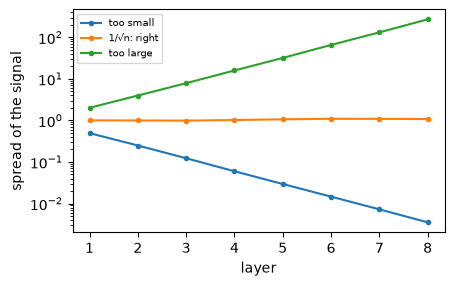

In [7]:
def activations_by_layer():
    r = np.random.default_rng(0)
    width = 100
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    for std, name in [(0.05, "too small"), (0.1, "1/√n: right"), (0.2, "too large")]:
        x = r.normal(size=(200, width))
        sizes = []
        for layer in range(8):
            x = x @ r.normal(0, std, (width, width))
            sizes.append(x.std())
        ax.semilogy(range(1, 9), sizes, "o-", markersize=3, label=name)
    ax.set_xlabel("layer")
    ax.set_ylabel("spread of the signal")
    ax.legend(fontsize=7)


activations_by_layer()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 8: The same network in PyTorch

*Level: Advanced*

PyTorch does the tensor maths on a GPU and **computes the gradients for you**. It doesn't run in this browser course, so run it on your own machine or in Colab.



```python
import torch
from torch import nn

model = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))

x = torch.randn(32, 784)             # a batch
y = torch.randint(0, 10, (32,))      # class labels

logits = model(x)                    # shape (32, 10)
loss = nn.CrossEntropyLoss()(logits, y)   # takes raw logits
loss.backward()                      # backpropagation

model[0].weight.grad.shape           # (256, 784)
```



**One difference:** PyTorch stores a linear layer's weights as (outputs, inputs), the opposite of the X·W form used in this course. That's why the gradient's shape is (256, 784).



Now `loss.backward()` isn't magic. It does what you wrote by hand in the previous lesson, for any model.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [8]:
W1 = [[0.5, -1.0, 2.0], [1.0, 0.0, -0.5]]

W2 = [[1.0], [-0.5], [0.25]]


<a id="q1"></a>
### Q1. Shape of a Nested List

🟢 Warm-up · *What a tensor is*

Return the shape of a rectangular nested list as a tuple.

**Examples**

- `x = [[1, 2, 3], [4, 5, 6]]` → `(2, 3)`
- `x = [[[1], [2]], [[3], [4]], [[5], [6]]]` → `(3, 2, 1)`
- `x = [1, 2]` → `(2,)`

In [ ]:
def shape_of(x):
    """
    Return the shape of a rectangular nested list as a tuple.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shape_of, [
    (([[1, 2, 3], [4, 5, 6]],), (2, 3)),
    (([[[1], [2]], [[3], [4]], [[5], [6]]],), (3, 2, 1)),
    (([1, 2],), (2,)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Keep stepping into the first element and record each length.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.shape(x)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Keep stepping into the first element and record each length.

```python
def shape_of(x):
    shape = []
    while isinstance(x, list):
        shape.append(len(x))
        x = x[0]
    return tuple(shape)
```

**Cost:** O(depth) time, O(depth) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.shape(x)`.

```python
def shape_of(x):
    return np.shape(x)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Keep stepping into the first element and record each length. That costs O(depth) time and O(depth) space."

"I can do better: `np.shape(x)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/shape-of-a-nested-list)

<a id="q2"></a>
### Q2. Flatten a Batch of Images

🟢 Warm-up · *(n, h, w) → (n, h·w)*

Turn each image in the batch into one long row.

**Examples**

- `batch = [[[1, 2], [3, 4]], [[5, 6], [7, 8]]]` → `[[1, 2, 3, 4], [5, 6, 7, 8]]`

In [ ]:
def flatten_images(batch):
    """
    Turn each image in the batch into one long row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(flatten_images, [
    (([[[1, 2], [3, 4]], [[5, 6], [7, 8]]],), [[1, 2, 3, 4], [5, 6, 7, 8]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops per image.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`x.reshape(len(x), -1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops per image.

```python
def flatten_images(batch):
    out = []
    for image in batch:
        row = []
        for line in image:
            row.extend(line)
        out.append(row)
    return out
```

**Cost:** O(n·h·w) time, O(n·h·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `x.reshape(len(x), -1)`.

```python
def flatten_images(batch):
    x = np.array(batch)
    return x.reshape(len(x), -1)
```

**Cost:** O(n·h·w) time, O(1) view space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops per image. That costs O(n·h·w) time and O(n·h·w) space."

"I can do better: `x.reshape(len(x), -1)`. That's O(n·h·w) time and O(1) view space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/flatten-a-batch-of-images)

<a id="q3"></a>
### Q3. Dense Layer Forward

🟢 Warm-up · *Z = X·W + b*

Compute a dense layer's outputs for a batch. W has one row per input feature and one column per output neuron.

**Examples**

- `X = [[1.0, 2.0], [0.0, -1.0], [3.0, 0.5]], W = [[0.5, -1.0, 2.0], [1.0, 0.0, -0.5]], b = [0.0, 1.0, -1.0]` → `[[2.5, 0.0, 0.0], [-1.0, 1.0, -0.5], [2.0, -2.0, 4.75]]`

In [ ]:
def dense(X, W, b):
    """
    Compute a dense layer's outputs for a batch. W has one row per input feature
    and one column per output neuron.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dense, [
    (([[1.0, 2.0], [0.0, -1.0], [3.0, 0.5]], [[0.5, -1.0, 2.0], [1.0, 0.0, -0.5]], [0.0, 1.0, -1.0]), [[2.5, 0.0, 0.0], [-1.0, 1.0, -0.5], [2.0, -2.0, 4.75]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Triple loop: each row, each neuron, each feature.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`X @ W + b`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Triple loop: each row, each neuron, each feature.

```python
def dense(X, W, b):
    out = []
    for row in X:
        outputs = []
        for k in range(len(b)):
            z = b[k]
            for j, x in enumerate(row):
                z += x * W[j][k]
            outputs.append(z)
        out.append(outputs)
    return out
```

**Cost:** O(n·d·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `X @ W + b`.

```python
def dense(X, W, b):
    return np.array(X) @ np.array(W) + np.array(b)
```

**Cost:** O(n·d·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Triple loop: each row, each neuron, each feature. That costs O(n·d·k) time and O(n·k) space."

"I can do better: `X @ W + b`. That's O(n·d·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/dense-layer-forward)

<a id="q4"></a>
### Q4. Model Memory

🟢 Warm-up · *Parameters × bytes*

Layer sizes are given. Return (parameter count, size in MB using 4 bytes per parameter, rounded to 3 decimals; 1 MB = 10⁶ bytes).

**Examples**

- `sizes = [784, 256, 10]` → `(203530, 0.814)`
- `sizes = [1000, 1000, 1000]` → `(2002000, 8.008)`

In [ ]:
def model_memory(sizes):
    """
    Layer sizes are given. Return (parameter count, size in MB using 4 bytes per
    parameter, rounded to 3 decimals; 1 MB = 10⁶ bytes).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(model_memory, [
    (([784, 256, 10],), (203530, 0.814)),
    (([1000, 1000, 1000],), (2002000, 8.008)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add weights and biases per layer in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `(a * b + b).sum()` on neighbouring sizes.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add weights and biases per layer in a loop.

```python
def model_memory(sizes):
    total = 0
    for a, b in zip(sizes, sizes[1:]):
        total += a * b + b
    return (total, round(total * 4 / 1e6, 3))
```

**Cost:** O(layers) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised: `(a * b + b).sum()` on neighbouring sizes.

```python
def model_memory(sizes):
    s = np.array(sizes)
    total = int((s[:-1] * s[1:] + s[1:]).sum())
    return (total, round(total * 4 / 1e6, 3))
```

**Cost:** O(layers) time, O(layers) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add weights and biases per layer in a loop. That costs O(layers) time and O(1) space."

"I can do better: Vectorised: `(a * b + b).sum()` on neighbouring sizes. That's O(layers) time and O(layers) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/model-memory)

<a id="q5"></a>
### Q5. One-Hot a Batch of Labels

🟢 Warm-up · *Targets for softmax*

Return a one-hot matrix for labels, with k classes.

**Examples**

- `y = [0, 2, 1], k = 3` → `[[1, 0, 0], [0, 0, 1], [0, 1, 0]]`

In [ ]:
def one_hot(y, k):
    """
    Return a one-hot matrix for labels, with k classes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(one_hot, [
    (([0, 2, 1], 3), [[1, 0, 0], [0, 0, 1], [0, 1, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build each row of zeros and set one position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.eye(k, dtype=int)[y]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Build each row of zeros and set one position.

```python
def one_hot(y, k):
    out = []
    for label in y:
        row = [0] * k
        row[label] = 1
        out.append(row)
    return out
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.eye(k, dtype=int)[y]`.

```python
def one_hot(y, k):
    return np.eye(k, dtype=int)[y]
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build each row of zeros and set one position. That costs O(n·k) time and O(n·k) space."

"I can do better: `np.eye(k, dtype=int)[y]`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/one-hot-a-batch-of-labels)

<a id="q6"></a>
### Q6. Mean Squared Error of a Batch

🟢 Warm-up · *Averaged over all entries*

Return the mean of (ŷ − y)² over every entry of two same-shaped tables, rounded to 4 decimals.

**Examples**

- `pred = [[1.0, 2.0], [3.0, 4.0]], target = [[1.0, 0.0], [5.0, 4.0]]` → `2.0`

In [ ]:
def batch_mse(pred, target):
    """
    Return the mean of (ŷ − y)² over every entry of two same-shaped tables,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(batch_mse, [
    (([[1.0, 2.0], [3.0, 4.0]], [[1.0, 0.0], [5.0, 4.0]]), 2.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`((a - b) ** 2).mean()`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two nested loops.

```python
def batch_mse(pred, target):
    total, count = 0.0, 0
    for r1, r2 in zip(pred, target):
        for a, b in zip(r1, r2):
            total += (a - b) ** 2
            count += 1
    return round(total / count, 4)
```

**Cost:** O(n·k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `((a - b) ** 2).mean()`.

```python
def batch_mse(pred, target):
    return round(((np.array(pred) - np.array(target)) ** 2).mean(), 4)
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two nested loops. That costs O(n·k) time and O(1) space."

"I can do better: `((a - b) ** 2).mean()`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/mean-squared-error-of-a-batch)

<a id="q7"></a>
### Q7. Accuracy From Logits

🟢 Warm-up · *Argmax*

Return the share of rows whose highest score is the true class, rounded to 4 decimals.

**Examples**

- `Z = [[2.0, 1.0], [0.0, 3.0], [1.0, 0.0]], y = [0, 1, 1]` → `0.6667`

In [ ]:
def logits_accuracy(Z, y):
    """
    Return the share of rows whose highest score is the true class, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(logits_accuracy, [
    (([[2.0, 1.0], [0.0, 3.0], [1.0, 0.0]], [0, 1, 1]), 0.6667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find each row's biggest position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(Z.argmax(axis=1) == y).mean()`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Find each row's biggest position.

```python
def logits_accuracy(Z, y):
    correct = 0
    for row, label in zip(Z, y):
        if row.index(max(row)) == label:
            correct += 1
    return round(correct / len(y), 4)
```

**Cost:** O(n·k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `(Z.argmax(axis=1) == y).mean()`.

```python
def logits_accuracy(Z, y):
    return round((np.array(Z).argmax(axis=1) == np.array(y)).mean(), 4)
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find each row's biggest position. That costs O(n·k) time and O(1) space."

"I can do better: `(Z.argmax(axis=1) == y).mean()`. That's O(n·k) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/accuracy-from-logits)

<a id="q8"></a>
### Q8. Top-k Predictions

🟢 Warm-up · *Most likely classes*

For each row return the indices of the k largest scores, largest first.

**Examples**

- `Z = [[0.1, 0.7, 0.2], [0.5, 0.2, 0.3]], k = 2` → `[[1, 2], [0, 2]]`

In [ ]:
def top_k(Z, k):
    """
    For each row return the indices of the k largest scores, largest first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_k, [
    (([[0.1, 0.7, 0.2], [0.5, 0.2, 0.3]], 2), [[1, 2], [0, 2]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort each row's indices by score.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.argsort(-Z, axis=1)[:, :k]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sort each row's indices by score.

```python
def top_k(Z, k):
    return [sorted(range(len(row)), key=lambda i: -row[i])[:k] for row in Z]
```

**Cost:** O(n·k log k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.argsort(-Z, axis=1)[:, :k]`.

```python
def top_k(Z, k):
    return np.argsort(-np.array(Z), axis=1)[:, :k]
```

**Cost:** O(n·k log k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort each row's indices by score. That costs O(n·k log k) time and O(n·k) space."

"I can do better: `np.argsort(-Z, axis=1)[:, :k]`. That's O(n·k log k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/top-k-predictions)

<a id="q9"></a>
### Q9. Steps per Epoch

🟢 Warm-up · *Batches and updates*

With n rows, a batch size and a number of epochs, return (steps per epoch, total updates). A smaller last batch still counts.

**Examples**

- `n = 10000, batch = 32, epochs = 10` → `(313, 3130)`
- `n = 64, batch = 32, epochs = 3` → `(2, 6)`

In [ ]:
def steps(n, batch, epochs):
    """
    With n rows, a batch size and a number of epochs, return (steps per epoch,
    total updates). A smaller last batch still counts.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(steps, [
    ((10000, 32, 10), (313, 3130)),
    ((64, 32, 3), (2, 6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count batches by walking through the rows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.ceil(n / batch)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count batches by walking through the rows.

```python
def steps(n, batch, epochs):
    count, start = 0, 0
    while start < n:
        count += 1
        start += batch
    return (count, count * epochs)
```

**Cost:** O(n / batch) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `math.ceil(n / batch)`.

```python
def steps(n, batch, epochs):
    per_epoch = math.ceil(n / batch)
    return (per_epoch, per_epoch * epochs)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count batches by walking through the rows. That costs O(n / batch) time and O(1) space."

"I can do better: `math.ceil(n / batch)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/steps-per-epoch)

<a id="q10"></a>
### Q10. Initialisation Scales

🟢 Warm-up · *Glorot and He*

Given fan\_in and fan\_out, return (Glorot std √(2/(in + out)), He std √(2/in)), rounded to 4 decimals.

**Examples**

- `fan_in = 100, fan_out = 100` → `(0.1, 0.1414)`
- `fan_in = 784, fan_out = 256` → `(0.0439, 0.0505)`

In [ ]:
def init_scales(fan_in, fan_out):
    """
    Given fan_in and fan_out, return (Glorot std √(2/(in + out)), He std
    √(2/in)), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(init_scales, [
    ((100, 100), (0.1, 0.1414)),
    ((784, 256), (0.0439, 0.0505)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the formulas with `math.sqrt`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same with `np.sqrt`, which works on arrays of layer sizes.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Apply the formulas with `math.sqrt`.

```python
def init_scales(fan_in, fan_out):
    return (round(math.sqrt(2 / (fan_in + fan_out)), 4), round(math.sqrt(2 / fan_in), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The same with `np.sqrt`, which works on arrays of layer sizes.

```python
def init_scales(fan_in, fan_out):
    return (round(np.sqrt(2 / (fan_in + fan_out)), 4), round(np.sqrt(2 / fan_in), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the formulas with `math.sqrt`. That costs O(1) time and O(1) space."

"I can do better: The same with `np.sqrt`, which works on arrays of layer sizes. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/initialisation-scales)

<a id="q11"></a>
### Q11. Broadcast Result Shape

🟡 Interview standard · *Will these tensors combine?*

Return the shape that two shapes broadcast to, or None if they can't.

**Examples**

- `a = (3, 1), b = (1, 4)` → `(3, 4)`
- `a = (2, 3), b = (3,)` → `(2, 3)`
- `a = (2, 3), b = (2,)` → `None`

In [ ]:
def broadcast_shape(a, b):
    """
    Return the shape that two shapes broadcast to, or None if they can't.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(broadcast_shape, [
    (((3, 1), (1, 4)), (3, 4)),
    (((2, 3), (3,)), (2, 3)),
    (((2, 3), (2,)), None),
    (((5, 1, 4), (3, 1)), (5, 3, 4)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare sizes from the right; each pair must match or contain a 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.broadcast_shapes`, which raises an error when they don't fit.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compare sizes from the right; each pair must match or contain a 1.

```python
def broadcast_shape(a, b):
    out = []
    for i in range(1, max(len(a), len(b)) + 1):
        x = a[-i] if i <= len(a) else 1
        y = b[-i] if i <= len(b) else 1
        if x != y and x != 1 and y != 1:
            return None
        out.append(max(x, y))
    return tuple(reversed(out))
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.broadcast_shapes`, which raises an error when they don't fit.

```python
def broadcast_shape(a, b):
    try:
        return np.broadcast_shapes(a, b)
    except ValueError:
        return None
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare sizes from the right; each pair must match or contain a 1. That costs O(d) time and O(d) space."

"I can do better: `np.broadcast_shapes`, which raises an error when they don't fit. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/broadcast-result-shape)

<a id="q12"></a>
### Q12. Two-Layer Forward Pass

🟡 Interview standard · *Input → ReLU → output*

Compute ReLU(X·W1 + b1)·W2 + b2 for a batch; round to 4 decimals.

**Examples**

- `X = [[1.0, 2.0], [0.0, -1.0], [3.0, 0.5]], W1 = [[0.5, -1.0, 2.0], [1.0, 0.0, -0.5]], b1 = [0.0, 1.0, -1.0], W2 = [[1.0], [-0.5], [0.25]], b2 = [0.5]` → `[[3.0], [0.0], [3.6875]]`

In [ ]:
def two_layers(X, W1, b1, W2, b2):
    """
    Compute ReLU(X·W1 + b1)·W2 + b2 for a batch; round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_layers, [
    (([[1.0, 2.0], [0.0, -1.0], [3.0, 0.5]], [[0.5, -1.0, 2.0], [1.0, 0.0, -0.5]], [0.0, 1.0, -1.0], [[1.0], [-0.5], [0.25]], [0.5]), [[3.0], [0.0], [3.6875]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops layer by layer.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Two matrix products.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops layer by layer.

```python
def two_layers(X, W1, b1, W2, b2):
    out = []
    for row in X:
        hidden = []
        for k in range(len(b1)):
            z = b1[k] + sum(x * W1[j][k] for j, x in enumerate(row))
            hidden.append(max(0.0, z))
        o = b2[0] + sum(h * W2[k][0] for k, h in enumerate(hidden))
        out.append([round(o, 4)])
    return out
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Two matrix products.

```python
def two_layers(X, W1, b1, W2, b2):
    H = np.maximum(0, np.array(X) @ np.array(W1) + np.array(b1))
    return (H @ np.array(W2) + np.array(b2)).round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops layer by layer. That costs O(n·params) time and O(n·h) space."

"I can do better: Two matrix products. That's O(n·params) time and O(n·h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/two-layer-forward-pass)

<a id="q13"></a>
### Q13. Softmax for a Batch, Safely

🟡 Interview standard · *No overflow*

Return softmax probabilities per row, rounded to 4 decimals. Must work for scores like 1000.

**Examples**

- `Z = [[2.0, 1.0, 0.0], [1000.0, 1000.0, 999.0]]` → `[[0.6652, 0.2447, 0.09], [0.4223, 0.4223, 0.1554]]`

In [ ]:
def softmax_batch(Z):
    """
    Return softmax probabilities per row, rounded to 4 decimals. Must work for
    scores like 1000.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(softmax_batch, [
    (([[2.0, 1.0, 0.0], [1000.0, 1000.0, 999.0]],), [[0.6652, 0.2447, 0.09], [0.4223, 0.4223, 0.1554]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract each row's max, then exponentiate and normalise in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same with `keepdims=True`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Subtract each row's max, then exponentiate and normalise in loops.

```python
def softmax_batch(Z):
    out = []
    for row in Z:
        top = max(row)
        e = [math.exp(v - top) for v in row]
        s = sum(e)
        out.append([round(v / s, 4) for v in e])
    return out
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The same with `keepdims=True`.

```python
def softmax_batch(Z):
    Z = np.array(Z, dtype=float)
    e = np.exp(Z - Z.max(axis=1, keepdims=True))
    return (e / e.sum(axis=1, keepdims=True)).round(4)
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract each row's max, then exponentiate and normalise in loops. That costs O(n·k) time and O(n·k) space."

"I can do better: The same with `keepdims=True`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/softmax-for-a-batch-safely)

<a id="q14"></a>
### Q14. Cross-Entropy From Logits

🟡 Interview standard · *Log-sum-exp*

Return the mean cross-entropy given raw scores Z and integer labels y, rounded to 4 decimals. Work directly with logs so that huge scores don't overflow.

**Examples**

- `Z = [[2.0, 1.0, 0.0], [0.0, 3.0, 0.0]], y = [0, 1]` → `0.2513`
- `Z = [[1000.0, 0.0], [0.0, 1000.0]], y = [0, 0]` → `500.0`

In [ ]:
def ce_from_logits(Z, y):
    """
    Return the mean cross-entropy given raw scores Z and integer labels y,
    rounded to 4 decimals. Work directly with logs so that huge scores don't
    overflow.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ce_from_logits, [
    (([[2.0, 1.0, 0.0], [0.0, 3.0, 0.0]], [0, 1]), 0.2513),
    (([[1000.0, 0.0], [0.0, 1000.0]], [0, 0]), 500.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each row: −(score of the true class) + log Σ e^score, using a shift by the max.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with the same shift.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** For each row: −(score of the true class) + log Σ e^score, using a shift by the max.

```python
def ce_from_logits(Z, y):
    total = 0.0
    for row, label in zip(Z, y):
        top = max(row)
        log_sum = top + math.log(sum(math.exp(v - top) for v in row))
        total += log_sum - row[label]
    return round(total / len(y), 4)
```

**Cost:** O(n·k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised with the same shift.

```python
def ce_from_logits(Z, y):
    Z = np.array(Z, dtype=float)
    shifted = Z - Z.max(axis=1, keepdims=True)
    log_p = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    return round(-log_p[np.arange(len(y)), y].mean(), 4)
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each row: −(score of the true class) + log Σ e^score, using a shift by the max. That costs O(n·k) time and O(1) space."

"I can do better: Vectorised with the same shift. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/cross-entropy-from-logits)

<a id="q15"></a>
### Q15. Binary Cross-Entropy From a Logit

🟡 Interview standard · *The stable formula*

Return the mean of max(z, 0) − z·y + log(1 + e^(−|z|)), the safe form of log-loss. Round to 4 decimals.

**Examples**

- `z = [2.0, -1.0, 0.0], y = [1, 0, 1]` → `0.3778`
- `z = [800.0], y = [0]` → `800.0`

In [ ]:
def bce_logits(z, y):
    """
    Return the mean of max(z, 0) − z·y + log(1 + e^(−|z|)), the safe form of
    log-loss. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bce_logits, [
    (([2.0, -1.0, 0.0], [1, 0, 1]), 0.3778),
    (([800.0], [0]), 800.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop using `math.log1p` and `math.exp`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised; `np.logaddexp(0, -z·s)` computes the same thing.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop using `math.log1p` and `math.exp`.

```python
def bce_logits(z, y):
    total = 0.0
    for score, label in zip(z, y):
        total += max(score, 0) - score * label + math.log1p(math.exp(-abs(score)))
    return round(total / len(z), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised; `np.logaddexp(0, -z·s)` computes the same thing.

```python
def bce_logits(z, y):
    z, y = np.array(z, dtype=float), np.array(y, dtype=float)
    return round(np.logaddexp(0, -z * (2 * y - 1)).mean(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop using `math.log1p` and `math.exp`. That costs O(n) time and O(1) space."

"I can do better: Vectorised; `np.logaddexp(0, -z·s)` computes the same thing. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/binary-cross-entropy-from-a-logit)

<a id="q16"></a>
### Q16. Shuffled Mini-Batches

🟡 Interview standard · *A new order each epoch*

Shuffle indices with np.random.RandomState(seed).permutation(n), then split into batches. Return the list of index batches.

**Examples**

- `n = 7, batch = 3, seed = 0` → `[[6, 2, 1], [3, 0, 5], [4]]`

In [ ]:
def shuffled_batches(n, batch, seed):
    """
    Shuffle indices with np.random.RandomState(seed).permutation(n), then split
    into batches. Return the list of index batches.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shuffled_batches, [
    ((7, 3, 0), [[6, 2, 1], [3, 0, 5], [4]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop, slicing the shuffled list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.array_split` at multiples of the batch size.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop, slicing the shuffled list.

```python
def shuffled_batches(n, batch, seed):
    order = np.random.RandomState(seed).permutation(n).tolist()
    return [order[i:i + batch] for i in range(0, n, batch)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.array_split` at multiples of the batch size.

```python
def shuffled_batches(n, batch, seed):
    order = np.random.RandomState(seed).permutation(n)
    return [part.tolist() for part in np.array_split(order, range(batch, n, batch))]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop, slicing the shuffled list. That costs O(n) time and O(n) space."

"I can do better: `np.array_split` at multiples of the batch size. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/shuffled-mini-batches)

<a id="q17"></a>
### Q17. Gradient of a Linear Layer

🟡 Interview standard · *∂MSE/∂W*

For Ŷ = X·W + b and MSE = mean((Ŷ − Y)²) over all entries, with one output column, return ∂/∂W as a column, rounded to 4 decimals.

**Examples**

- `X = [[1.0, 2.0], [3.0, 4.0]], Y = [[1.0], [2.0]], W = [[0.5], [-0.5]], b = [0.0]` → `[[-9.0], [-13.0]]`

In [ ]:
def linear_grad(X, Y, W, b):
    """
    For Ŷ = X·W + b and MSE = mean((Ŷ − Y)²) over all entries, with one output
    column, return ∂/∂W as a column, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(linear_grad, [
    (([[1.0, 2.0], [3.0, 4.0]], [[1.0], [2.0]], [[0.5], [-0.5]], [0.0]), [[-9.0], [-13.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops: each row adds 2·error·x to each weight's gradient, then divide by n.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`2 * X.T @ (Y_hat - Y) / n`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops: each row adds 2·error·x to each weight's gradient, then divide by n.

```python
def linear_grad(X, Y, W, b):
    n, d = len(X), len(X[0])
    grad = [0.0] * d
    for row, target in zip(X, Y):
        pred = b[0] + sum(x * W[j][0] for j, x in enumerate(row))
        for j, x in enumerate(row):
            grad[j] += 2 * (pred - target[0]) * x / n
    return [[round(g, 4)] for g in grad]
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `2 * X.T @ (Y_hat - Y) / n`.

```python
def linear_grad(X, Y, W, b):
    X, Y, W = np.array(X), np.array(Y), np.array(W)
    return (2 * X.T @ (X @ W + np.array(b) - Y) / len(X)).round(4)
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops: each row adds 2·error·x to each weight's gradient, then divide by n. That costs O(n·d) time and O(d) space."

"I can do better: `2 * X.T @ (Y_hat - Y) / n`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/gradient-of-a-linear-layer)

<a id="q18"></a>
### Q18. Gradient Check

🟡 Interview standard · *Catching backprop bugs*

Return the relative error ‖a − n‖ / (‖a‖ + ‖n‖) between an analytic and a numerical gradient, rounded to 6 decimals. Under about 1e-5 is healthy.

**Examples**

- `analytic = [1.0, 2.0], numeric = [1.0, 2.00001]` → `0.0`
- `analytic = [1.0, 2.0], numeric = [1.0, 3.0]` → `0.1852`

In [ ]:
def grad_check(analytic, numeric):
    """
    Return the relative error ‖a − n‖ / (‖a‖ + ‖n‖) between an analytic and a
    numerical gradient, rounded to 6 decimals. Under about 1e-5 is healthy.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(grad_check, [
    (([1.0, 2.0], [1.0, 2.00001]), 0.0),
    (([1.0, 2.0], [1.0, 3.0]), 0.1852),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Square, sum and root in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.norm`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Square, sum and root in loops.

```python
def grad_check(analytic, numeric):
    top = math.sqrt(sum((a - n) ** 2 for a, n in zip(analytic, numeric)))
    bottom = math.sqrt(sum(a * a for a in analytic)) + math.sqrt(sum(n * n for n in numeric))
    return round(top / bottom, 6)
```

**Cost:** O(d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.linalg.norm`.

```python
def grad_check(analytic, numeric):
    a, n = np.array(analytic), np.array(numeric)
    return round(np.linalg.norm(a - n) / (np.linalg.norm(a) + np.linalg.norm(n)), 6)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Square, sum and root in loops. That costs O(d) time and O(1) space."

"I can do better: `np.linalg.norm`. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/gradient-check)

<a id="q19"></a>
### Q19. Variance Through a Layer

🟡 Interview standard · *Why scale matters*

If inputs have variance v and weights variance w, each output of a linear layer with n inputs has variance n·w·v. Starting from v = 1, return the variance after each of L layers, using the given weight std.

**Examples**

- `n = 100, std = 0.1, L = 3` → `[1.0, 1.0, 1.0]`
- `n = 100, std = 0.2, L = 3` → `[4.0, 16.0, 64.0]`
- `n = 100, std = 0.05, L = 3` → `[0.25, 0.0625, 0.0156]`

In [ ]:
def variance_through(n, std, L):
    """
    If inputs have variance v and weights variance w, each output of a linear
    layer with n inputs has variance n·w·v. Starting from v = 1, return the
    variance after each of L layers, using the given weight std.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(variance_through, [
    ((100, 0.1, 3), [1.0, 1.0, 1.0]),
    ((100, 0.2, 3), [4.0, 16.0, 64.0]),
    ((100, 0.05, 3), [0.25, 0.0625, 0.0156]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop, multiplying by n·std² each layer.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Powers: `(n * std**2) ** np.arange(1, L + 1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop, multiplying by n·std² each layer.

```python
def variance_through(n, std, L):
    out = []
    v = 1.0
    for _ in range(L):
        v = n * std * std * v
        out.append(round(v, 4))
    return out
```

**Cost:** O(L) time, O(L) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Powers: `(n * std**2) ** np.arange(1, L + 1)`.

```python
def variance_through(n, std, L):
    return ((n * std ** 2) ** np.arange(1, L + 1)).round(4)
```

**Cost:** O(L) time, O(L) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop, multiplying by n·std² each layer. That costs O(L) time and O(L) space."

"I can do better: Powers: `(n * std**2) ** np.arange(1, L + 1)`. That's O(L) time and O(L) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/variance-through-a-layer)

<a id="q20"></a>
### Q20. Backprop Through Two Layers

🔴 Stretch · *Matrix gradients*

Network: H = tanh(X·W1 + b1), Ŷ = H·W2 + b2, loss ½·mean((Ŷ − Y)²). Return the gradient for W1, rounded to 4 decimals.

**Examples**

- `X = [[1.0, 2.0], [0.0, 1.0]], Y = [[1.0], [0.0]], W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3], [-0.6]], b2 = [0.2]` → `[[-0.0736, 0.2072], [-0.1351, 0.3912]]`

In [ ]:
def backprop_w1(X, Y, W1, b1, W2, b2):
    """
    Network: H = tanh(X·W1 + b1), Ŷ = H·W2 + b2, loss ½·mean((Ŷ − Y)²). Return
    the gradient for W1, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(backprop_w1, [
    (([[1.0, 2.0], [0.0, 1.0]], [[1.0], [0.0]], [[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3], [-0.6]], [0.2]), [[-0.0736, 0.2072], [-0.1351, 0.3912]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical: nudge every weight in W1 and watch the loss.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Backprop: error × W2ᵀ × (1 − H²), then Xᵀ× that, divided by n.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Numerical: nudge every weight in W1 and watch the loss.

```python
def backprop_w1(X, Y, W1, b1, W2, b2):
    def loss(W):
        total = 0.0
        for row, target in zip(X, Y):
            hidden = [math.tanh(b1[k] + sum(x * W[j][k] for j, x in enumerate(row))) for k in range(len(b1))]
            pred = b2[0] + sum(h * W2[k][0] for k, h in enumerate(hidden))
            total += (pred - target[0]) ** 2
        return total / (2 * len(X))

    h = 1e-6
    grad = []
    for j in range(len(W1)):
        line = []
        for k in range(len(W1[0])):
            up = [list(r) for r in W1]
            down = [list(r) for r in W1]
            up[j][k] += h
            down[j][k] -= h
            line.append(round((loss(up) - loss(down)) / (2 * h), 4))
        grad.append(line)
    return grad
```

**Cost:** O(params·n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Backprop: error × W2ᵀ × (1 − H²), then Xᵀ× that, divided by n.

```python
def backprop_w1(X, Y, W1, b1, W2, b2):
    X, Y, W1, W2 = map(np.array, (X, Y, W1, W2))
    H = np.tanh(X @ W1 + np.array(b1))
    error = H @ W2 + np.array(b2) - Y
    dH = error @ W2.T * (1 - H ** 2)
    return (X.T @ dH / len(X)).round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical: nudge every weight in W1 and watch the loss. That costs O(params·n) time and O(1) space."

"I can do better: Backprop: error × W2ᵀ × (1 − H²), then Xᵀ× that, divided by n. That's O(n·params) time and O(n·h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/tensors/backprop-through-two-layers)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why do we use batches?</b></summary>

A batch gradient is a cheap, reasonably accurate estimate of the full gradient. GPUs also process many examples in parallel. Noise from small batches is often harmless or even helpful.

</details>

<details>
<summary><b>2. What are logits?</b></summary>

The raw, unnormalised outputs of the last layer. Softmax or sigmoid turns them into probabilities.

</details>

<details>
<summary><b>3. Why can't all weights start at zero?</b></summary>

Neurons in a layer would stay identical, because they'd compute the same output and get the same gradient. Random starts break this symmetry.

</details>

<details>
<summary><b>4. Glorot vs He initialisation?</b></summary>

Both keep signal variance steady across layers. Glorot suits tanh and sigmoid; He doubles the variance for ReLU, which silences about half its inputs.

</details>

<details>
<summary><b>5. What does loss.backward() do?</b></summary>

It walks the recorded computation backwards with the chain rule, storing each parameter's gradient in its .grad field.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What deep learning adds
- [ ] I can explain: Tensors and shapes
- [ ] I can explain: A dense layer by hand
- [ ] I can explain: From logits to a loss, safely
- [ ] I can explain: Batches, steps and epochs
- [ ] I can explain: Backpropagation with matrices
- [ ] I can explain: Initialisation: why the starting numbers matter
- [ ] I can explain: The same network in PyTorch

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Shuffled Mini-Batches
- [ ] [Q17](#q17) Gradient of a Linear Layer
- [ ] [Q18](#q18) Gradient Check
- [ ] [Q19](#q19) Variance Through a Layer
- [ ] [Q20](#q20) Backprop Through Two Layers

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.